# GoL-EM — Multi-Task / Multi-Config Runner

Runs the Game-of-Life arithmetic Emergent Model over **several arithmetic tasks** and
**several configs**, in series, training each `(task, config)` pair with random search
**until convergence**, and saving the best program to disk.

**Convergence** (random search has no true fixed point, so we use practical stopping rules):
- **solved** — the best genome reaches `TARGET_EXACT` exact-match fraction on the training set, or
- **stalled** — no improvement in best loss for `PATIENCE` generations, or
- **max_gen** — `MAX_GENERATIONS` reached.

**What is saved** — for each pair, `results_multitask/<task>__<config>.npz` contains (via
`save_genome`):
- `positions` — glider anchor coordinates `(n_gliders, 2)`  → the **glider positions**,
- `active` — glider on/off bits `(n_gliders,)`,
- `program_board` — the rendered `Lp×Lp` binary program region  → the **raw pattern**,
- `best_loss / best_mae / best_invalid / best_exact / best_interact / best_multi`,
- `config` — the full task+config dict.

A `results_multitask/summary.csv` aggregates all runs.

> Requires a CUDA GPU + `taichi`. If you have no GPU, change `ti.init(arch=ti.cuda)` to
> `ti.init(arch=ti.cpu)` in the setup cell (slower).


In [1]:
from pathlib import Path
import time
import numpy as np
import taichi as ti

from utils import (
    init_population,
    evaluate_population_dataset,
    render_program_board,
    save_genome,
    TaichiGoLBatch,
)

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results_multitask"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Use ti.cpu instead of ti.cuda if you have no CUDA GPU.
ti.init(arch=ti.cuda)

print("project dir:", PROJECT_DIR)
print("results dir:", RESULTS_DIR.resolve())


[Taichi] version 1.7.4, llvm 15.0.1, commit b4b956fd, win, python 3.12.10
[Taichi] Starting on arch=cuda
project dir: c:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm
results dir: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm\results_multitask


In [2]:
# ---------------------------------------------------------------------
# Tasks
# ---------------------------------------------------------------------
# Each task fn must be vectorized over a numpy int array and return
# non-negative integers (the positional decoder cannot represent negatives).
# Note: Le must be wide enough to hold the largest OUTPUT block during training.

TASKS = [
    dict(name="x_plus_1",  fn=lambda x: x + 1, train_lo=0, train_hi=10),
    dict(name="x_minus_1", fn=lambda x: x - 1, train_lo=1, train_hi=11),
    dict(name="x_plus_2",  fn=lambda x: x + 2, train_lo=0, train_hi=10),
    dict(name="x_minus_2", fn=lambda x: x - 2, train_lo=2, train_hi=12),
    dict(name="x_plus_5",  fn=lambda x: x + 5, train_lo=0, train_hi=10),
    dict(name="x_minus_5", fn=lambda x: x - 5, train_lo=5, train_hi=15),
]

# ---------------------------------------------------------------------
# Configs (tried in order for each task)
# ---------------------------------------------------------------------
# NOTE: every element MUST be a dict. To disable a config, delete it or
# comment EACH line with '#'. Do NOT wrap it in triple quotes: that turns
# it into a string element and breaks the loop with
# "TypeError: string indices must be integers".
CONFIGS = [
    dict(
        name="g2",
        P=5000, Lp=16, Ls=6, Le=40, s=2,
        n_gliders=2, p_active_on=0.95, T_max=600,
        k_invalid=1.6, k_interact=0.6, k_exact=0.1, k_multi=0.01,
    ),
    # dict(
    #     name="g3",
    #     P=5000, Lp=16, Ls=6, Le=40, s=2,
    #     n_gliders=3, p_active_on=0.95, T_max=800,
    #     k_invalid=1.6, k_interact=0.6, k_exact=0.1, k_multi=0.01,
    # ),
]

# ---------------------------------------------------------------------
# Convergence / run controls
# ---------------------------------------------------------------------
MAX_GENERATIONS   = 8       # hard cap on random-search rounds per (task, config)
PATIENCE          = 8       # stop if best loss does not improve for this many rounds
MIN_DELTA         = 1e-3    # minimum loss improvement counted as progress
TARGET_EXACT      = 1.0     # early-stop when best genome is exact on the whole train set
STOP_TASK_ON_SOLVE = True   # once a config solves a task, skip remaining configs for it
SEED              = 0

# Guard: fail loudly with a clear message instead of a cryptic TypeError.
assert isinstance(TASKS, list) and all(isinstance(t, dict) for t in TASKS), "TASKS must be a list of dicts"
assert isinstance(CONFIGS, list) and all(isinstance(c, dict) for c in CONFIGS), "CONFIGS must be a list of dicts"

print(f"{len(TASKS)} tasks x {len(CONFIGS)} configs")


6 tasks x 1 configs


In [3]:
# ---------------------------------------------------------------------
# Simulator cache + training-until-convergence
# ---------------------------------------------------------------------
METRIC_KEYS = ("loss", "mae", "invalid", "exact", "interact", "multi")

_SIM_CACHE = {}

def get_simulator(cfg):
    """One Taichi simulator per distinct (P, Lp, Ls, Le, n_gliders, s) signature."""
    key = (cfg["P"], cfg["Lp"], cfg["Ls"], cfg["Le"], cfg["n_gliders"], cfg["s"])
    if key not in _SIM_CACHE:
        _SIM_CACHE[key] = TaichiGoLBatch(
            B=cfg["P"], Lp=cfg["Lp"], Ls=cfg["Ls"], Le=cfg["Le"],
            n_gliders=cfg["n_gliders"], s=cfg["s"],
        )
    return _SIM_CACHE[key]


def train_until_convergence(task, cfg, rng, *, max_generations, patience, min_delta,
                            target_exact, verbose=True):
    xs = np.arange(task["train_lo"], task["train_hi"], dtype=np.int32)
    ys = task["fn"](xs).astype(np.float32)
    sim = get_simulator(cfg)

    best = None
    best_loss = np.inf
    best_gen = -1
    no_improve = 0
    reason = "max_gen"
    t0 = time.perf_counter()

    gen = 0
    for gen in range(1, max_generations + 1):
        positions, active = init_population(
            pop_size=cfg["P"], n_gliders=cfg["n_gliders"],
            Lp=cfg["Lp"], p_active_on=cfg["p_active_on"], rng=rng,
        )
        metrics, _ = evaluate_population_dataset(
            sim, positions, active, xs, ys, cfg["T_max"],
            k_invalid=cfg["k_invalid"], k_interact=cfg["k_interact"],
            k_exact=cfg["k_exact"], k_multi=cfg["k_multi"],
        )

        idx = int(np.argmin(metrics["loss"]))
        gen_loss = float(metrics["loss"][idx])

        if gen_loss < best_loss - min_delta:
            best_loss = gen_loss
            best_gen = gen
            no_improve = 0
            best = dict(
                positions=positions[idx].copy(),
                active=active[idx].copy(),
                metrics={k: float(metrics[k][idx]) for k in METRIC_KEYS},
            )
        else:
            no_improve += 1

        if verbose and (gen == 1 or gen % 10 == 0):
            print(f"  gen={gen:4d}  best_loss={best_loss:.4f}  "
                  f"best_exact={best['metrics']['exact']:.3f}  no_improve={no_improve}")

        if best["metrics"]["exact"] >= target_exact:
            reason = "solved"
            break
        if no_improve >= patience:
            reason = "stalled"
            break

    best["gen_found"] = best_gen
    best["generations_run"] = gen
    best["reason"] = reason
    best["train_exact"] = best["metrics"]["exact"]
    best["elapsed_s"] = time.perf_counter() - t0
    return best


In [4]:
# ---------------------------------------------------------------------
# Main loop: every (task, config) pair, in series
# ---------------------------------------------------------------------
rng = np.random.default_rng(SEED)
summary = []

for task in TASKS:
    print(f"\n=== TASK: {task['name']}  (train x in [{task['train_lo']},{task['train_hi']})) ===")
    task_solved = False

    for cfg in CONFIGS:
        if STOP_TASK_ON_SOLVE and task_solved:
            print(f"  [skip config {cfg['name']}] task already solved")
            continue

        print(f"-- config: {cfg['name']}  (n_gliders={cfg['n_gliders']}, T_max={cfg['T_max']}) --")
        best = train_until_convergence(
            task, cfg, rng,
            max_generations=MAX_GENERATIONS, patience=PATIENCE,
            min_delta=MIN_DELTA, target_exact=TARGET_EXACT,
        )

        out_path = RESULTS_DIR / f"{task['name']}__{cfg['name']}.npz"
        full_cfg = dict(
            task_name=task["name"],
            train_lo=int(task["train_lo"]), train_hi=int(task["train_hi"]),
            reason=best["reason"], gen_found=int(best["gen_found"]),
            generations_run=int(best["generations_run"]),
            **{k: cfg[k] for k in cfg},
        )
        save_genome(
            path=out_path,
            positions=best["positions"], active=best["active"],
            metrics=best["metrics"], config=full_cfg, Lp=cfg["Lp"],
        )

        board = render_program_board(best["positions"], best["active"], cfg["Lp"])
        print(f"  -> saved {out_path.name}  reason={best['reason']}  "
              f"train_exact={best['train_exact']:.3f}  loss={best['metrics']['loss']:.4f}  "
              f"gliders_on={int(best['active'].sum())}  live_cells={int(board.sum())}  "
              f"gen_found={best['gen_found']}  elapsed={best['elapsed_s']:.1f}s")

        summary.append(dict(
            task=task["name"], config=cfg["name"], reason=best["reason"],
            train_exact=best["train_exact"], loss=best["metrics"]["loss"],
            mae=best["metrics"]["mae"], invalid=best["metrics"]["invalid"],
            gen_found=best["gen_found"], generations_run=best["generations_run"],
            elapsed_s=round(best["elapsed_s"], 1), file=out_path.name,
        ))

        if best["train_exact"] >= TARGET_EXACT:
            task_solved = True

print("\nAll (task, config) pairs done.")



=== TASK: x_plus_1  (train x in [0,10)) ===
-- config: g2  (n_gliders=2, T_max=600) --


c:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm\utils.py:395: SyntaxWarning: You are unrolling more than
                        32 iterations, so the compile time may be extremely long.
                        You can use a non-static for loop if you want to decrease the compile time.
                        You can disable this warning by setting ti.init(unrolling_limit=0).
  for di, dj in ti.static(ti.ndrange(6, 6)):


  gen=   1  best_loss=-0.7000  best_exact=1.000  no_improve=0
  -> saved x_plus_1__g2.npz  reason=solved  train_exact=1.000  loss=-0.7000  gliders_on=2  live_cells=10  gen_found=1  elapsed=8.7s

=== TASK: x_minus_1  (train x in [1,11)) ===
-- config: g2  (n_gliders=2, T_max=600) --
  gen=   1  best_loss=-0.7000  best_exact=1.000  no_improve=0
  -> saved x_minus_1__g2.npz  reason=solved  train_exact=1.000  loss=-0.7000  gliders_on=2  live_cells=10  gen_found=1  elapsed=6.8s

=== TASK: x_plus_2  (train x in [0,10)) ===
-- config: g2  (n_gliders=2, T_max=600) --
  gen=   1  best_loss=-0.7000  best_exact=1.000  no_improve=0
  -> saved x_plus_2__g2.npz  reason=solved  train_exact=1.000  loss=-0.7000  gliders_on=2  live_cells=10  gen_found=1  elapsed=6.8s

=== TASK: x_minus_2  (train x in [2,12)) ===
-- config: g2  (n_gliders=2, T_max=600) --
  gen=   1  best_loss=-0.7000  best_exact=1.000  no_improve=0
  -> saved x_minus_2__g2.npz  reason=solved  train_exact=1.000  loss=-0.7000  gliders_on=

In [5]:
# ---------------------------------------------------------------------
# Summary table
# ---------------------------------------------------------------------
import pandas as pd

df = pd.DataFrame(summary)
csv_path = RESULTS_DIR / "summary.csv"
df.to_csv(csv_path, index=False)
print("summary saved:", csv_path.resolve())
df


summary saved: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-arithm\results_multitask\summary.csv


,task,config,reason,train_exact,loss,mae,invalid,gen_found,generations_run,elapsed_s,file
0,x_plus_1,g2,solved,1.0,-0.700,0.0,0.0,1,1,8.7,x_plus_1__g2.npz
1,x_minus_1,g2,solved,1.0,-0.700,0.0,0.0,1,1,6.8,x_minus_1__g2.npz
2,x_plus_2,g2,solved,1.0,-0.700,0.0,0.0,1,1,6.8,x_plus_2__g2.npz
3,x_minus_2,g2,solved,1.0,-0.700,0.0,0.0,1,1,6.9,x_minus_2__g2.npz
4,x_plus_5,g2,solved,1.0,-0.700,0.0,0.0,1,1,6.9,x_plus_5__g2.npz
5,x_minus_5,g2,solved,1.0,-0.691,0.0,0.0,1,1,6.9,x_minus_5__g2.npz


## Optional: inspect a saved program and check extrapolation

Loads one saved `.npz`, shows its raw program pattern, and runs the CPU self-extending
evaluator on a larger input range to measure exact-match extrapolation. The task function is
looked up from `TASKS` (defined above) by the `task_name` stored in the file.


file: x_plus_5__g2.npz
saved train_exact: 1.0  reason: solved
glider positions:
 [[11 15]
 [ 1  4]]
active: [1 1]


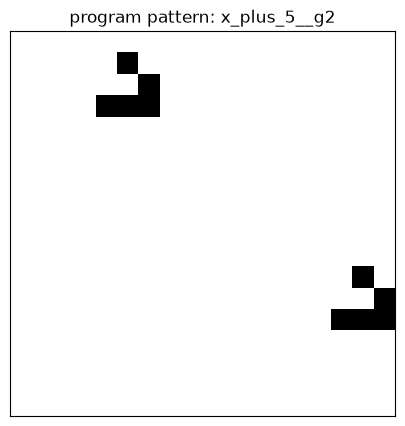


extrapolation (x in [0,60)):
{'n': 60, 'valid_rate': 1.0, 'exact_rate': 1.0, 'mae_valid': 0.0, 'mean_extensions': 0.8166666666666667, 'max_final_side': 162, 'max_steps_run': 567}


In [6]:
import matplotlib.pyplot as plt
from utils import evaluate_genome_dataset_cpu, plot_board

# Pick a saved result (edit the index / filename as you like).
saved_files = sorted(RESULTS_DIR.glob("*.npz"))
if not saved_files:
    raise FileNotFoundError("No saved genomes found. Run the main loop first.")

LOAD_FILE = saved_files[5]
z = np.load(LOAD_FILE, allow_pickle=True)

positions = z["positions"]
active = z["active"]
cfgd = z["config"].item()
Lp, Ls, Le, s = int(cfgd["Lp"]), int(cfgd["Ls"]), int(cfgd["Le"]), int(cfgd["s"])

print("file:", LOAD_FILE.name)
print("saved train_exact:", float(z["best_exact"]), " reason:", str(cfgd.get("reason")))
print("glider positions:\n", positions)
print("active:", active)

# Raw program pattern (the Lp x Lp region).
plot_board(z["program_board"], title=f"program pattern: {LOAD_FILE.stem}")
plt.show()

# Extrapolation eval on a larger range, if the task fn is available.
task_by_name = {t["name"]: t for t in TASKS}
tname = str(cfgd["task_name"])
if tname in task_by_name:
    fn = task_by_name[tname]["fn"]
    xs_test = np.arange(0, 60, dtype=np.int32)
    ys_test = fn(xs_test).astype(np.float32)
    summary_eval, records = evaluate_genome_dataset_cpu(
        positions=positions, active=active,
        xs=xs_test, ys=ys_test,
        Lp=Lp, Ls=Ls, Le=Le, T_max=3000, s=s,
        progress=False,
    )
    print("\nextrapolation (x in [0,60)):")
    print(summary_eval)
else:
    print(f"task '{tname}' not found in TASKS; skipping extrapolation eval.")
